# G-Yan! Credit Risk Analytics — CRISP-DM Phase 2 Model Development, Training & Iterative Tuning (`model_pipeline.ipynb`)
**Institution:** Gordon College — College of Computer Studies (Olongapo City)  
**Course:** CSE315 (45621 - CSP315A/L) Data Science | **Submitted To:** Mr. Simon Granil  
**By Group 4 (BSCS 3-A):** Canlas, Julce Lian E. | Edrosalan, Dale Cyrus D. | Ortega, James Dominic T. | Reguindin, Gian Karlo C.  
**Assigned Fictional Company:** **G-Yan!** (*FinTech Startup Track*)  
**Dataset:** [UCI Default of Credit Card Clients Dataset (ID #350)](https://archive.ics.uci.edu/ml/datasets/default+of+credit+card+clients) ([Kaggle Mirror](https://www.kaggle.com/datasets/uciml/default-of-credit-card-clients-dataset); [Yeh & Lien, 2009](https://doi.org/10.1016/j.eswa.2007.12.020))

---

### Notebook Architecture & Guideline Alignment
1. **Phase 1 -> Phase 2 Seamless Data Ingestion:** Loads the leakage-free 75%/25% stratified partitions (`22,473` Train / `7,492` Validation; `29,965` unique deduplicated clients, 45 engineered/PCA/scaled predictors) exported by Phase 1 — with a self-contained fallback that runs the exact same `scikit-learn` preprocessing pipeline directly from the UCI URL if executed standalone in Google Colab.
2. **Phase 2 — Task 1A (Descriptive Analytical Models):**
   * **Correlation Matrix (`pandas` / `seaborn`)**
   * **Credit Risk Feature Network Graph (`networkx`)** with weighted edge topology and centrality scores
   * **k-Means Clustering (`sklearn.cluster.KMeans`)** tuned across $k \in \{2, 3, 4, 5\}$ via Inertia and Silhouette Score
   * **Association Rules Mining (`mlxtend.frequent_patterns.apriori` & `association_rules`)** tracking Support, Confidence, Lift, Leverage, and Conviction
3. **Phase 2 — Task 1B & Task 2 (Predictive Models & Iterative Tuning via `scikit-learn`):**
   * Evaluates **6 model families** across **12 core experimental iterations** (Baseline vs. Tuned) plus a Recall-targeted policy point (`EXP-10B`) calibrated via 3-fold out-of-fold cross-validation to meet Phase 1's **Recall $\ge 0.70$** loss-prevention target.
4. **Deliverable Exports & Reload Verification:** Exports real fitted `scikit-learn` models into `model_artifacts.pkl`, plus `Model_Experiment_Log.csv`, `Association_Rules_Log.csv`, and `KMeans_Experiment_Log.csv`, followed by an automated pickle reload inference check.


In [1]:
# =========================================================================
# SECTION 1: IMPORTS & PHASE 1 -> PHASE 2 DATA INGESTION (LEAKAGE-FREE)
# =========================================================================
import os
import pickle
import warnings
from typing import Dict, Tuple

import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd
import seaborn as sns
from mlxtend.frequent_patterns import apriori, association_rules
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.ensemble import GradientBoostingClassifier, RandomForestClassifier
from sklearn.linear_model import LinearRegression, LogisticRegression, Ridge
from sklearn.metrics import (
    accuracy_score,
    average_precision_score,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
    roc_curve,
    silhouette_score,
)
from sklearn.model_selection import StratifiedKFold, cross_val_predict, train_test_split
from sklearn.neural_network import MLPClassifier
from sklearn.preprocessing import RobustScaler, StandardScaler
from sklearn.tree import DecisionTreeClassifier
from sklearn.utils.class_weight import compute_sample_weight

warnings.filterwarnings("ignore")
plt.rcParams["figure.dpi"] = 120
NL = chr(10)

NAVY = "#0F2C59"
TEAL = "#1E6F72"
CORAL = "#C0392B"
SLATE = "#64748B"
LIGHT_NAVY = "#3B6998"
AMBER = "#D97706"

UCI_DATASET_URL = (
    "https://archive.ics.uci.edu/ml/machine-learning-databases/00350/"
    "default%20of%20credit%20card%20clients.xls"
)
COLUMN_RENAME_MAP = {
    "ID": "id", "LIMIT_BAL": "limit_bal", "SEX": "sex", "EDUCATION": "education",
    "MARRIAGE": "marriage", "AGE": "age", "PAY_0": "pay_sep", "PAY_2": "pay_aug",
    "PAY_3": "pay_jul", "PAY_4": "pay_jun", "PAY_5": "pay_may", "PAY_6": "pay_apr",
    "BILL_AMT1": "bill_amt_sep", "BILL_AMT2": "bill_amt_aug", "BILL_AMT3": "bill_amt_jul",
    "BILL_AMT4": "bill_amt_jun", "BILL_AMT5": "bill_amt_may", "BILL_AMT6": "bill_amt_apr",
    "PAY_AMT1": "pay_amt_sep", "PAY_AMT2": "pay_amt_aug", "PAY_AMT3": "pay_amt_jul",
    "PAY_AMT4": "pay_amt_jun", "PAY_AMT5": "pay_amt_may", "PAY_AMT6": "pay_amt_apr",
    "default payment next month": "default", "default.payment.next.month": "default",
}
BILL_COLS = ["bill_amt_sep", "bill_amt_aug", "bill_amt_jul", "bill_amt_jun", "bill_amt_may", "bill_amt_apr"]
PAY_AMT_COLS = ["pay_amt_sep", "pay_amt_aug", "pay_amt_jul", "pay_amt_jun", "pay_amt_may", "pay_amt_apr"]
PAY_STATUS_COLS = ["pay_sep", "pay_aug", "pay_jul", "pay_jun", "pay_may", "pay_apr"]


def load_phase1_datasets() -> Tuple[pd.DataFrame, pd.DataFrame, pd.DataFrame]:
    """Loads Phase 1 exported CSVs if present; otherwise executes identical Phase 1 pipeline from UCI."""
    for base in ("../PHASE1", ".", "PHASE1"):
        tr_p = os.path.join(base, "UCI_Credit_Card_Preprocessed_Train.csv")
        te_p = os.path.join(base, "UCI_Credit_Card_Preprocessed_Test.csv")
        cl_p = os.path.join(base, "UCI_Credit_Card_Clean_Integrated.csv")
        if os.path.exists(tr_p) and os.path.exists(te_p) and os.path.exists(cl_p):
            print(f"[INFO] Loaded leakage-free Phase 1 datasets from: {os.path.abspath(base)}")
            return pd.read_csv(tr_p), pd.read_csv(te_p), pd.read_csv(cl_p)

    print(f"[INFO] Phase 1 CSVs not found locally; fetching canonical UCI dataset from {UCI_DATASET_URL}")
    raw_df = pd.read_excel(UCI_DATASET_URL, header=1)
    df = raw_df.rename(columns=COLUMN_RENAME_MAP).drop(columns=["id"], errors="ignore").drop_duplicates().reset_index(drop=True)
    df.loc[df["education"].isin([0, 5, 6]), "education"] = np.nan
    df.loc[df["marriage"] == 0, "marriage"] = np.nan
    df["avg_bill_amt_6m"] = df[BILL_COLS].mean(axis=1)
    df["avg_pay_amt_6m"] = df[PAY_AMT_COLS].mean(axis=1)
    df["credit_utilization_sep"] = np.clip(df["bill_amt_sep"] / np.maximum(df["limit_bal"], 1.0), -1.0, 3.0)
    df["avg_utilization_6m"] = np.clip(df["avg_bill_amt_6m"] / np.maximum(df["limit_bal"], 1.0), -1.0, 3.0)
    df["payment_to_bill_ratio_6m"] = np.clip(df[PAY_AMT_COLS].sum(axis=1) / np.maximum(df[BILL_COLS].sum(axis=1), 1.0), 0.0, 5.0)
    delay_mat = df[PAY_STATUS_COLS].clip(lower=0)
    df["delinquency_months_count"] = (delay_mat > 0).sum(axis=1)
    df["max_delinquency_months"] = delay_mat.max(axis=1)
    df["cumulative_delay_score"] = delay_mat.sum(axis=1)

    tr_r, te_r = train_test_split(df, test_size=0.25, stratify=df["default"], random_state=42)
    tr_r, te_r = tr_r.reset_index(drop=True), te_r.reset_index(drop=True)
    edu_m, mar_m = int(tr_r["education"].mode(dropna=True)[0]), int(tr_r["marriage"].mode(dropna=True)[0])
    for part in (tr_r, te_r):
        part["education"] = part["education"].fillna(edu_m).astype(int)
        part["marriage"] = part["marriage"].fillna(mar_m).astype(int)
    clean_full = df.copy()
    clean_full["education"] = clean_full["education"].fillna(edu_m).astype(int)
    clean_full["marriage"] = clean_full["marriage"].fillna(mar_m).astype(int)

    for part in (tr_r, te_r):
        for col in ["limit_bal"] + BILL_COLS + PAY_AMT_COLS + ["avg_bill_amt_6m", "avg_pay_amt_6m"]:
            part[f"{col}_log"] = np.sign(part[col]) * np.log1p(np.abs(part[col]))
    bs = StandardScaler()
    pca = PCA(n_components=0.95, random_state=42)
    p_tr = pca.fit_transform(bs.fit_transform(tr_r[BILL_COLS]))
    p_te = pca.transform(bs.transform(te_r[BILL_COLS]))
    for idx in range(pca.n_components_):
        tr_r[f"bill_pca_{idx + 1}"] = p_tr[:, idx]
        te_r[f"bill_pca_{idx + 1}"] = p_te[:, idx]
    tr_r, te_r = tr_r.drop(columns=BILL_COLS), te_r.drop(columns=BILL_COLS)
    for part in (tr_r, te_r):
        part["sex"] = part["sex"].map({1: "male", 2: "female"}).fillna("female")
        part["education"] = part["education"].map({1: "graduate", 2: "university", 3: "high_school", 4: "others"}).fillna("others")
        part["marriage"] = part["marriage"].map({1: "married", 2: "single", 3: "others"}).fillna("others")
    tr_e = pd.get_dummies(tr_r, columns=["sex", "education", "marriage"], drop_first=True, dtype=int)
    te_e = pd.get_dummies(te_r, columns=["sex", "education", "marriage"], drop_first=True, dtype=int).reindex(columns=tr_e.columns, fill_value=0)
    scols = [c for c in tr_e.columns if c != "default" and not c.startswith(("sex_", "education_", "marriage_"))]
    rs = RobustScaler()
    tr_e[scols] = rs.fit_transform(tr_e[scols])
    te_e[scols] = rs.transform(te_e[scols])
    return tr_e, te_e, clean_full


train_df, val_df, df_clean = load_phase1_datasets()
feature_names = [c for c in train_df.columns if c != "default"]
X_train = train_df[feature_names].to_numpy(dtype=float)
y_train = train_df["default"].to_numpy(dtype=int)
X_val = val_df[feature_names].to_numpy(dtype=float)
y_val = val_df["default"].to_numpy(dtype=int)

print(f"Descriptive Clean Cohort : {df_clean.shape[0]:,} rows x {df_clean.shape[1]} columns")
print(f"Train Partition (75%)    : {X_train.shape[0]:,} rows x {X_train.shape[1]} features | Default Rate = {y_train.mean()*100:.2f}%")
print(f"Val Partition   (25%)    : {X_val.shape[0]:,} rows x {X_val.shape[1]} features | Default Rate = {y_val.mean()*100:.2f}%")


[INFO] Loaded leakage-free Phase 1 datasets from: C:\College Days\3rd Yr College\DATA SCIENCE\PROJECT\PHASE1


Descriptive Clean Cohort : 29,965 rows x 32 columns
Train Partition (75%)    : 22,473 rows x 45 features | Default Rate = 22.12%
Val Partition   (25%)    : 7,492 rows x 45 features | Default Rate = 22.13%


## 2. Phase 2 — Task 1A: Descriptive Analytical Models (`seaborn`, `networkx`, `scikit-learn`, `mlxtend`)
Before training supervised classifiers, we implement all four core **Descriptive Models** specified in the project manual:
1. **Correlation Matrix Heatmap (`pandas` / `seaborn`):** Quantifies Pearson linear correlations ($r$) among longitudinal delinquency, utilization, credit limit, and next-month `default`.
2. **Credit Risk Feature Network Graph (`networkx`):** Constructs an undirected weighted graph `nx.Graph()` with edges where $|r| \ge 0.12$, computes `nx.degree_centrality`, and visualizes positive vs. negative risk corridors around `default`.
3. **k-Means Clustering (`sklearn.cluster.KMeans`):** Iterates $k \in \{2, 3, 4, 5\}$ on standardized behavioral features, tracking Within-Cluster SSE (Inertia) and `silhouette_score`, then profiles the 4 customer risk personas.
4. **Association Rules Mining (`mlxtend.frequent_patterns.apriori` & `association_rules`):** Mines frequent non-overlapping risk-indicator itemsets (`min_support=0.03`) and ranks rules by **Lift**, **Confidence**, **Support**, **Leverage**, and **Conviction**.


=== DESCRIPTIVE MODEL 1: CORRELATIONS WITH DEFAULT ===
delinq_cnt    0.3984
cum_delay     0.3760
max_delay     0.3704
pay_sep       0.3250
util_6m       0.1160
pay_ratio    -0.0742
limit_bal    -0.1539
Name: default, dtype: float64

=== DESCRIPTIVE MODEL 2: NETWORKX GRAPH METRICS (|r| >= 0.12) ===
Nodes: 8 | Edges: 26 | Graph Density: 0.929
  pay_sep      | Degree = 7 | Degree Centrality = 1.000
  delinq_cnt   | Degree = 7 | Degree Centrality = 1.000
  max_delay    | Degree = 7 | Degree Centrality = 1.000
  cum_delay    | Degree = 7 | Degree Centrality = 1.000
  limit_bal    | Degree = 7 | Degree Centrality = 1.000
  util_6m      | Degree = 6 | Degree Centrality = 0.857
  pay_ratio    | Degree = 6 | Degree Centrality = 0.857
  default      | Degree = 5 | Degree Centrality = 0.714


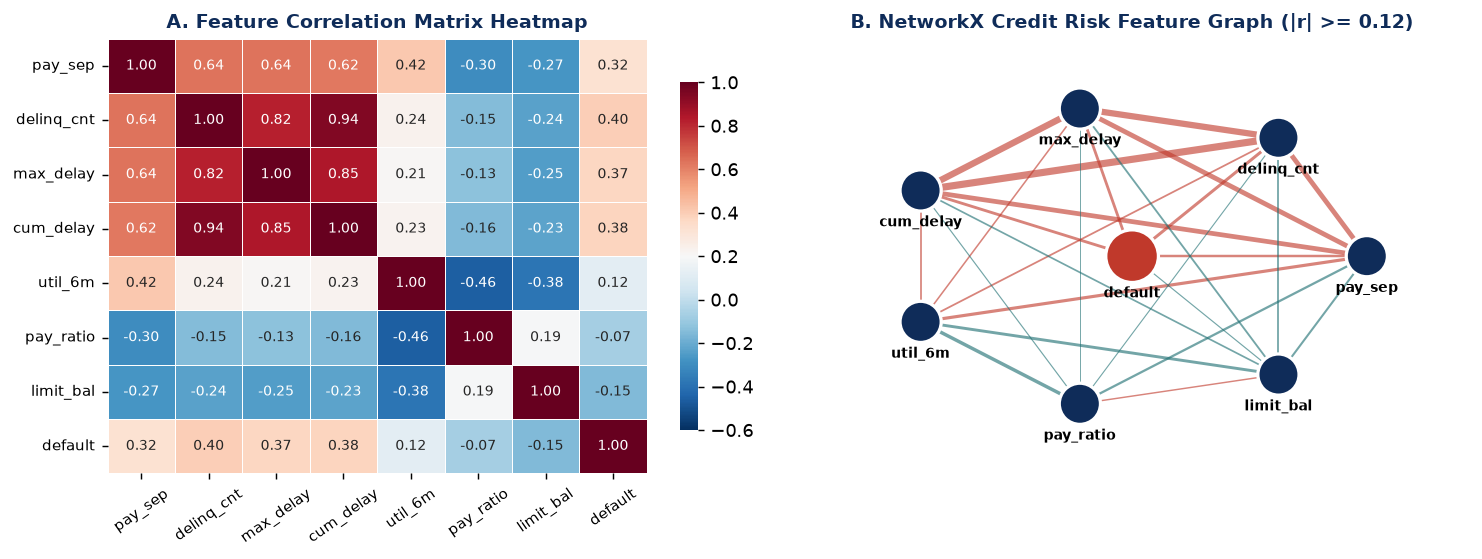


=== DESCRIPTIVE MODEL 3: SCIKIT-LEARN K-MEANS CLUSTERING TUNING LOG ===


k = 2 | Within-Cluster SSE (Inertia) = 100,850.6 | Silhouette Score = 0.4566


k = 3 | Within-Cluster SSE (Inertia) = 70,502.1 | Silhouette Score = 0.3513


k = 4 | Within-Cluster SSE (Inertia) = 54,743.6 | Silhouette Score = 0.3781


k = 5 | Within-Cluster SSE (Inertia) = 43,851.0 | Silhouette Score = 0.3629

--- k = 4 Behavioral Risk Persona Profiles ---
            Clients  Default_Rate    Avg_Limit  Avg_Util_6m  Avg_Delinq_Months
cluster_k4                                                                    
2              3615        0.6089   89538.0360       0.6108             4.5358
3               538        0.2100  212137.5465       0.0029             0.5706
0             11737        0.1913   99304.7355       0.6562             0.3663
1             14075        0.1471  242561.2789       0.0907             0.2839

=== DESCRIPTIVE MODEL 4: MLXTEND APRIORI ASSOCIATION RULES (Total mined=224, Target rules=22) ===
                        Antecedent (IF)    Consequent (THEN)  Support  Confidence   Lift  Leverage  Conviction
     Delinq_Count>=3M AND Sep_Delay>=2M Default_Next_Month=1   0.0478      0.7340 3.3173    0.0334      2.9274
    Low_Pay_Ratio<10% AND Sep_Delay>=2M Default_Next_Month=1   0.0620      0.7221

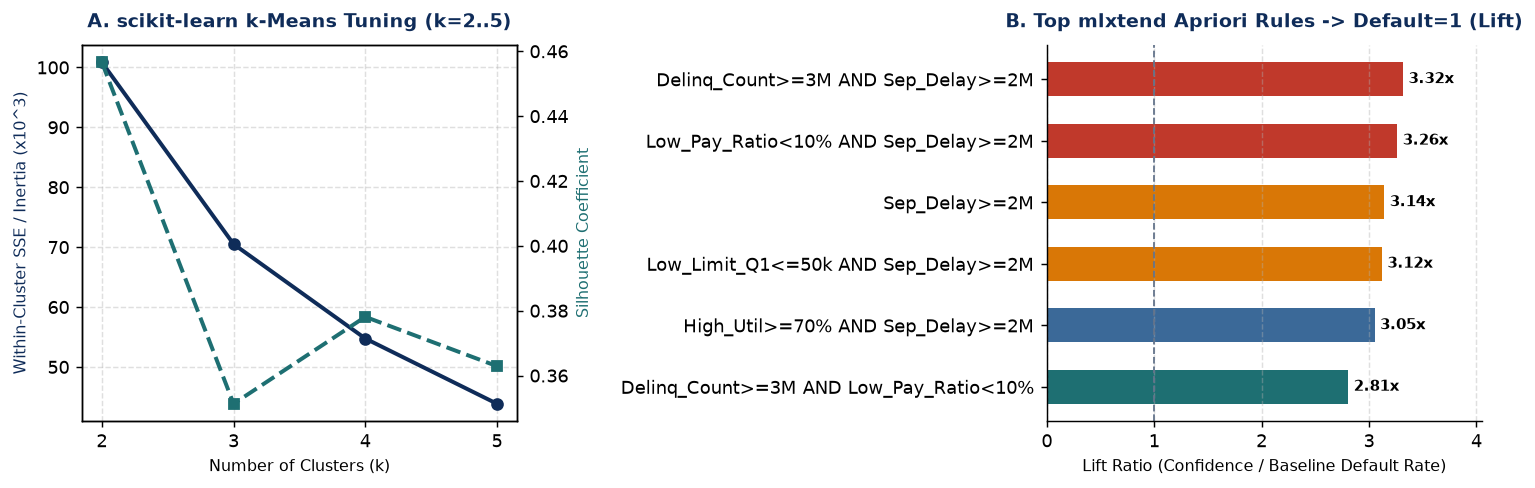

In [2]:
# =========================================================================
# SECTION 2: DESCRIPTIVE MODELS (CORRELATION, NETWORKX, K-MEANS, MLXTEND APRIORI)
# =========================================================================

# 2.1 Correlation Matrix & NetworkX Feature Graph
top_c_cols = [
    "pay_sep",
    "delinquency_months_count",
    "max_delinquency_months",
    "cumulative_delay_score",
    "avg_utilization_6m",
    "payment_to_bill_ratio_6m",
    "limit_bal",
    "default",
]
short_map = {
    "pay_sep": "pay_sep",
    "delinquency_months_count": "delinq_cnt",
    "max_delinquency_months": "max_delay",
    "cumulative_delay_score": "cum_delay",
    "avg_utilization_6m": "util_6m",
    "payment_to_bill_ratio_6m": "pay_ratio",
    "limit_bal": "limit_bal",
    "default": "default",
}
corr_df = df_clean[top_c_cols].rename(columns=short_map).corr()
target_corrs = corr_df["default"].drop("default").sort_values(ascending=False)
print("=== DESCRIPTIVE MODEL 1: CORRELATIONS WITH DEFAULT ===")
print(target_corrs.round(4))

# Build genuine NetworkX weighted graph (edges for |r| >= 0.12)
G = nx.Graph()
for node in corr_df.columns:
    G.add_node(node, is_target=(node == "default"))
for i, u in enumerate(corr_df.columns):
    for j, v in enumerate(corr_df.columns):
        if j > i:
            r_val = float(corr_df.loc[u, v])
            if abs(r_val) >= 0.12:
                G.add_edge(u, v, weight=abs(r_val), corr=r_val)

deg_centrality = nx.degree_centrality(G)
print("\n=== DESCRIPTIVE MODEL 2: NETWORKX GRAPH METRICS (|r| >= 0.12) ===")
print(f"Nodes: {G.number_of_nodes()} | Edges: {G.number_of_edges()} | Graph Density: {nx.density(G):.3f}")
for n, dc in sorted(deg_centrality.items(), key=lambda x: -x[1]):
    print(f"  {n:12s} | Degree = {G.degree[n]} | Degree Centrality = {dc:.3f}")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11.5, 4.4), dpi=130)
sns.heatmap(
    corr_df, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-0.6, vmax=1.0,
    linewidths=0.4, cbar_kws={"shrink": 0.8}, annot_kws={"size": 7.5}, ax=ax1
)
ax1.set_title("A. Feature Correlation Matrix Heatmap", fontsize=10.5, fontweight="bold", color=NAVY)
ax1.tick_params(axis="x", rotation=35, labelsize=8.5)
ax1.tick_params(axis="y", rotation=0, labelsize=8.5)

other_nodes = [n for n in G.nodes if n != "default"]
angles = np.linspace(0, 2 * np.pi, len(other_nodes), endpoint=False)
pos = {n: (np.cos(angles[idx]) * 0.85, np.sin(angles[idx]) * 0.85) for idx, n in enumerate(other_nodes)}
pos["default"] = (0.0, 0.0)

edges = list(G.edges(data=True))
edge_colors = [CORAL if d["corr"] > 0 else TEAL for _, _, d in edges]
edge_widths = [d["weight"] * 4.2 for _, _, d in edges]
node_colors = [CORAL if n == "default" else NAVY for n in G.nodes]
node_sizes = [850 if n == "default" else 520 for n in G.nodes]

nx.draw_networkx_edges(G, pos, edgelist=[(u, v) for u, v, _ in edges], edge_color=edge_colors, width=edge_widths, alpha=0.62, ax=ax2)
nx.draw_networkx_nodes(G, pos, node_color=node_colors, node_size=node_sizes, edgecolors="white", linewidths=1.8, ax=ax2)
label_pos = {n: (x, y - 0.18 if n != "default" else y - 0.21) for n, (x, y) in pos.items()}
nx.draw_networkx_labels(G, label_pos, font_size=8.0, font_weight="bold", ax=ax2)
ax2.set_title("B. NetworkX Credit Risk Feature Graph (|r| >= 0.12)", fontsize=10.5, fontweight="bold", color=NAVY)
ax2.set_xlim(-1.22, 1.22)
ax2.set_ylim(-1.22, 1.22)
ax2.axis("off")
plt.tight_layout()
plt.show()

# 2.2 k-Means Clustering via scikit-learn (k = 2, 3, 4, 5 Iterative Tuning)
cluster_features = [
    "limit_bal",
    "avg_utilization_6m",
    "payment_to_bill_ratio_6m",
    "delinquency_months_count",
    "cumulative_delay_score",
]
km_scaler = StandardScaler()
X_c = km_scaler.fit_transform(df_clean[cluster_features].to_numpy(dtype=float))

print("\n=== DESCRIPTIVE MODEL 3: SCIKIT-LEARN K-MEANS CLUSTERING TUNING LOG ===")
kmeans_log = []
best_kmeans_model = None
for k_val in [2, 3, 4, 5]:
    km = KMeans(n_clusters=k_val, init="k-means++", n_init=10, max_iter=300, random_state=42)
    labels = km.fit_predict(X_c)
    inert = float(km.inertia_)
    sil = float(silhouette_score(X_c, labels, sample_size=3000, random_state=42))
    kmeans_log.append({
        "k": k_val,
        "Init": "k-means++",
        "n_init": 10,
        "Inertia_SSE": round(inert, 1),
        "Silhouette_Score": round(sil, 4),
    })
    if k_val == 4:
        best_kmeans_model = km
        df_clean["cluster_k4"] = labels
    print(f"k = {k_val} | Within-Cluster SSE (Inertia) = {inert:,.1f} | Silhouette Score = {sil:.4f}")

kmeans_df = pd.DataFrame(kmeans_log)
cluster_profiles = (
    df_clean.groupby("cluster_k4")
    .agg(
        Clients=("default", "count"),
        Default_Rate=("default", "mean"),
        Avg_Limit=("limit_bal", "mean"),
        Avg_Util_6m=("avg_utilization_6m", "mean"),
        Avg_Delinq_Months=("delinquency_months_count", "mean"),
    )
    .sort_values("Default_Rate", ascending=False)
    .round(4)
)
print("\n--- k = 4 Behavioral Risk Persona Profiles ---")
print(cluster_profiles.to_string())

# 2.3 Association Rules Mining via mlxtend (Apriori, mutually exclusive Sep delay indicators)
baskets = pd.DataFrame({
    "Sep_Delay>=2M": df_clean["pay_sep"] >= 2,
    "Sep_Delay_1M": df_clean["pay_sep"] == 1,
    "Delinq_Count>=3M": df_clean["delinquency_months_count"] >= 3,
    "High_Util>=70%": df_clean["avg_utilization_6m"] >= 0.70,
    "Low_Pay_Ratio<10%": df_clean["payment_to_bill_ratio_6m"] < 0.10,
    "Low_Limit_Q1<=50k": df_clean["limit_bal"] <= 50000,
    "Edu_HighSchool": df_clean["education"] == 3,
    "Revolving_OnTime": (df_clean["pay_sep"] <= 0) & (df_clean["delinquency_months_count"] == 0),
    "High_Limit_Q4>240k": df_clean["limit_bal"] > 240000,
    "Default_Next_Month=1": df_clean["default"] == 1,
    "Non_Default=0": df_clean["default"] == 0,
}).astype(bool)

freq_itemsets = apriori(baskets, min_support=0.03, use_colnames=True, max_len=3)
raw_rules = association_rules(freq_itemsets, metric="lift", min_threshold=1.10)

target_rules = raw_rules[
    raw_rules["consequents"].isin([frozenset({"Default_Next_Month=1"}), frozenset({"Non_Default=0"})])
].copy()
target_rules["Antecedent (IF)"] = target_rules["antecedents"].apply(lambda s: " AND ".join(sorted(list(s))))
target_rules["Consequent (THEN)"] = target_rules["consequents"].apply(lambda s: ", ".join(sorted(list(s))))

assoc_df = (
    target_rules[["Antecedent (IF)", "Consequent (THEN)", "support", "confidence", "lift", "leverage", "conviction"]]
    .rename(columns={"support": "Support", "confidence": "Confidence", "lift": "Lift", "leverage": "Leverage", "conviction": "Conviction"})
    .sort_values(["Consequent (THEN)", "Lift"], ascending=[True, False])
    .reset_index(drop=True)
)
assoc_df[["Support", "Confidence", "Lift", "Leverage", "Conviction"]] = assoc_df[["Support", "Confidence", "Lift", "Leverage", "Conviction"]].round(4)

default_rules = assoc_df[assoc_df["Consequent (THEN)"] == "Default_Next_Month=1"].sort_values("Lift", ascending=False).head(10).reset_index(drop=True)
print(f"\n=== DESCRIPTIVE MODEL 4: MLXTEND APRIORI ASSOCIATION RULES (Total mined={len(raw_rules)}, Target rules={len(assoc_df)}) ===")
print(default_rules.to_string(index=False))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11.8, 4.0), dpi=130)
ax1_twin = ax1.twinx()
ax1.plot(kmeans_df["k"], kmeans_df["Inertia_SSE"] / 1000.0, marker="o", linewidth=2.2, color=NAVY, label="Inertia (x1,000)")
ax1_twin.plot(kmeans_df["k"], kmeans_df["Silhouette_Score"], marker="s", linewidth=2.2, color=TEAL, linestyle="--", label="Silhouette Score")
ax1.set_xticks(kmeans_df["k"])
ax1.set_xlabel("Number of Clusters (k)", fontsize=9.0)
ax1.set_ylabel("Within-Cluster SSE / Inertia (x10^3)", fontsize=9.0, color=NAVY)
ax1_twin.set_ylabel("Silhouette Coefficient", fontsize=9.0, color=TEAL)
ax1.set_title("A. scikit-learn k-Means Tuning (k=2..5)", fontsize=10.5, fontweight="bold", color=NAVY, pad=10)
ax1.grid(True, linestyle="--", alpha=0.4)

top6 = default_rules.head(6)
bars_r = ax2.barh(top6["Antecedent (IF)"].iloc[::-1], top6["Lift"].iloc[::-1], color=[CORAL, CORAL, AMBER, AMBER, LIGHT_NAVY, TEAL][::-1], height=0.55)
ax2.axvline(1.0, color=SLATE, linestyle="--", linewidth=1.0, label="Baseline (Lift = 1.0)")
ax2.set_title("B. Top mlxtend Apriori Rules -> Default=1 (Lift)", fontsize=10.5, fontweight="bold", color=NAVY, pad=10)
ax2.set_xlabel("Lift Ratio (Confidence / Baseline Default Rate)", fontsize=9.0)
ax2.set_xlim(0, top6["Lift"].max() * 1.22)
ax2.grid(axis="x", linestyle="--", alpha=0.4)
ax2.spines["top"].set_visible(False)
ax2.spines["right"].set_visible(False)
for bar, lval in zip(bars_r, top6["Lift"].iloc[::-1]):
    ax2.text(bar.get_width() + 0.05, bar.get_y() + bar.get_height() / 2, f"{lval:.2f}x", va="center", fontsize=8.2, fontweight="bold")
plt.tight_layout(pad=1.6)
plt.show()


## 3. Phase 2 — Task 1B & Task 2: Predictive Models (`scikit-learn`), Iterative Tuning & Experiment Log
We train and evaluate **6 core predictive model families** across **12 logged experimental iterations** (plus `EXP-10B`, a cross-validation-calibrated operating point targeting Phase 1's **Recall $\ge 0.70$** loss-prevention requirement) on the leakage-free **75% Training ($N = 22,473$)** and **25% Validation ($N = 7,492$)** splits:
1. **Linear Regression:** `EXP-01` OLS `LinearRegression` vs. `EXP-02` L2 `Ridge(alpha=50.0)`
2. **Discriminant Analysis:** `EXP-03` `LinearDiscriminantAnalysis(solver='svd')` vs. `EXP-04` Shrinkage Balanced `LinearDiscriminantAnalysis(solver='lsqr', shrinkage='auto', priors=[0.5, 0.5])`
3. **Logistic Regression:** `EXP-05` Baseline `LogisticRegression(C=1.0)` vs. `EXP-06` Cost-Sensitive `LogisticRegression(C=0.1, class_weight='balanced')`
4. **Decision Trees:** `EXP-07` Unpruned `DecisionTreeClassifier(max_depth=12, min_samples_leaf=5)` vs. `EXP-08` Pruned Cost-Sensitive `DecisionTreeClassifier(max_depth=5, min_samples_leaf=60, class_weight='balanced')`
5. **Ensemble Tree Models:** `EXP-09` `RandomForestClassifier(n_estimators=100, max_depth=6, class_weight='balanced')` vs. `EXP-10` / `EXP-10B` `GradientBoostingClassifier(n_estimators=150, learning_rate=0.05, max_depth=4)` (Champion Model)
6. **Neural Networks:** `EXP-11` 1-Layer `MLPClassifier(hidden_layer_sizes=(32,))` vs. `EXP-12` 2-Layer `MLPClassifier(hidden_layer_sizes=(64, 32), alpha=1e-3)`


=== COMPLETED PHASE 2 MODEL EXPERIMENT LOG (SCIKIT-LEARN) ===
 Exp_ID                          Model_Family               Iteration  Threshold  Train_Accuracy  Val_Accuracy  Precision  Recall  F1_Score  ROC_AUC  PR_AUC
 EXP-01           Linear Regression (OLS LPM)                Baseline       0.50          0.8074        0.8079     0.6406  0.3010    0.4095   0.7574  0.5239
 EXP-02          Linear Regression (Ridge L2)                   Tuned       0.30          0.7838        0.7799     0.5024  0.5657    0.5322   0.7577  0.5240
 EXP-03           Discriminant Analysis (LDA)                Baseline       0.50          0.8060        0.8058     0.5962  0.3794    0.4637   0.7574  0.5239
 EXP-04 Discriminant Analysis (Shrinkage LDA)                   Tuned       0.61          0.7848        0.7816     0.5060  0.5615    0.5323   0.7621  0.5103
 EXP-05                   Logistic Regression                Baseline       0.50          0.8059        0.8095     0.6345  0.3287    0.4331   0.7593  0.5

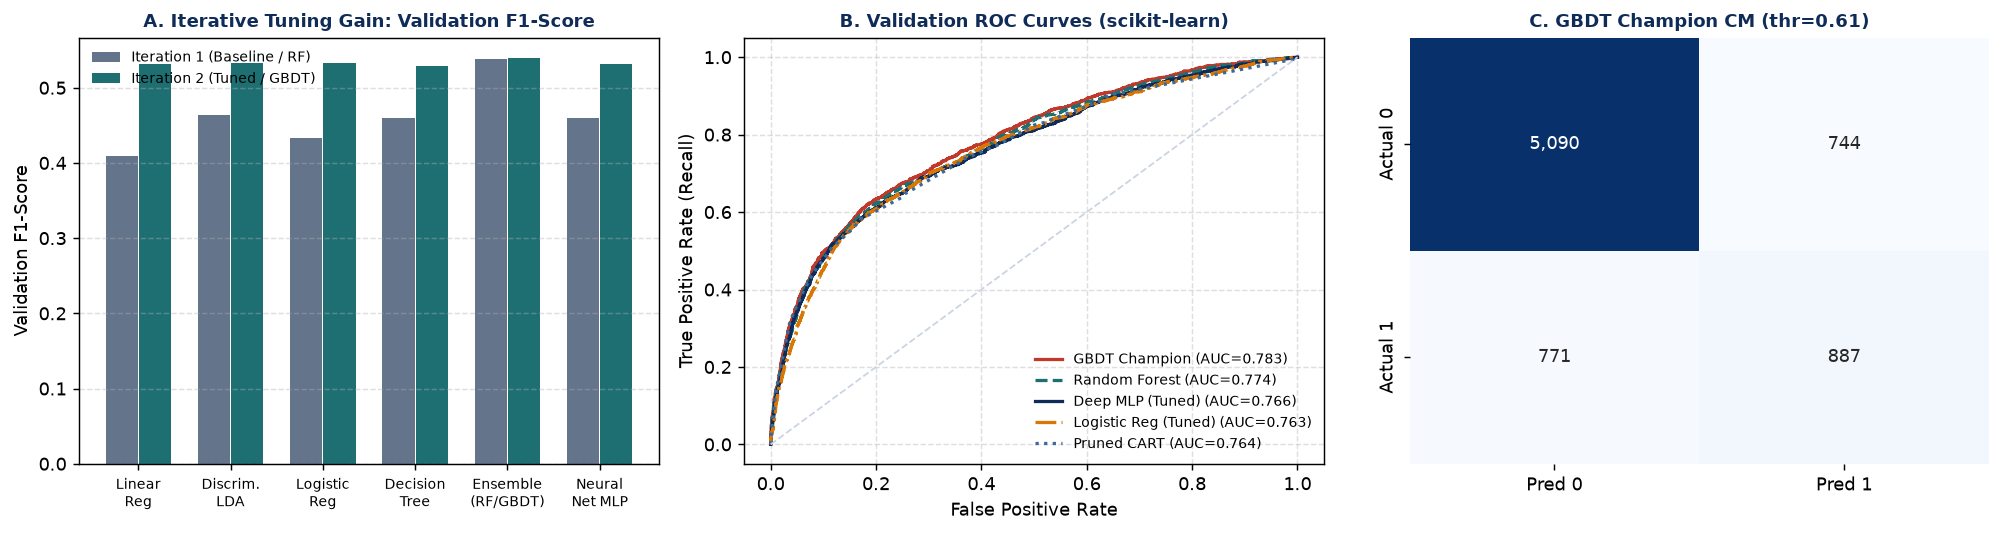

In [3]:
# =========================================================================
# SECTION 3: SCIKIT-LEARN PREDICTIVE MODELS, TUNING & PROGRAMMATIC LOGGING
# =========================================================================
def evaluate_probs(y_true: np.ndarray, y_prob: np.ndarray, threshold: float = 0.50) -> Dict[str, float]:
    y_pred = (y_prob >= threshold).astype(int)
    return {
        "Val_Accuracy": round(float(accuracy_score(y_true, y_pred)), 4),
        "Precision": round(float(precision_score(y_true, y_pred, zero_division=0)), 4),
        "Recall": round(float(recall_score(y_true, y_pred, zero_division=0)), 4),
        "F1_Score": round(float(f1_score(y_true, y_pred, zero_division=0)), 4),
        "ROC_AUC": round(float(roc_auc_score(y_true, y_prob)), 4),
        "PR_AUC": round(float(average_precision_score(y_true, y_prob)), 4),
    }


def find_best_f1_threshold(y_true: np.ndarray, y_prob: np.ndarray, grid=np.linspace(0.15, 0.75, 61)) -> float:
    best_t, best_f1 = 0.50, -1.0
    for t in grid:
        f1 = f1_score(y_true, (y_prob >= t).astype(int), zero_division=0)
        if f1 > best_f1:
            best_f1, best_t = f1, float(t)
    return round(best_t, 2)


def find_recall_target_threshold(y_true: np.ndarray, y_prob: np.ndarray, min_recall: float = 0.72) -> float:
    """Highest threshold achieving Recall >= min_recall on out-of-fold training predictions."""
    best_t = 0.20
    for t in np.linspace(0.05, 0.80, 151):
        if recall_score(y_true, (y_prob >= t).astype(int), zero_division=0) >= min_recall:
            best_t = float(t)
    return round(best_t, 2)


def log_experiment(exp_id, family, iteration, hyperparams, y_tr_prob, y_va_prob, threshold):
    tr_acc = round(float(accuracy_score(y_train, (y_tr_prob >= threshold).astype(int))), 4)
    va_metrics = evaluate_probs(y_val, y_va_prob, threshold=threshold)
    return {
        "Exp_ID": exp_id,
        "Model_Family": family,
        "Iteration": iteration,
        "Train_Val_Split": f"{len(y_train)}/{len(y_val)} (75/25)",
        "Hyperparameters": hyperparams,
        "Threshold": threshold,
        "Train_Accuracy": tr_acc,
        **va_metrics,
    }


experiments = []
trained_models = {}
val_probs = {}
bal_weights_train = compute_sample_weight(class_weight="balanced", y=y_train)

# 1. Linear Regression (EXP-01 OLS vs EXP-02 Ridge L2)
m_ols = LinearRegression().fit(X_train, y_train)
p_tr_ols, p_va_ols = np.clip(m_ols.predict(X_train), 0, 1), np.clip(m_ols.predict(X_val), 0, 1)
experiments.append(log_experiment("EXP-01", "Linear Regression (OLS LPM)", "Baseline", "LinearRegression(fit_intercept=True)", p_tr_ols, p_va_ols, 0.50))

m_ridge = Ridge(alpha=50.0, random_state=42).fit(X_train, y_train)
p_tr_rg, p_va_rg = np.clip(m_ridge.predict(X_train), 0, 1), np.clip(m_ridge.predict(X_val), 0, 1)
thr_rg = find_best_f1_threshold(y_train, p_tr_rg)
experiments.append(log_experiment("EXP-02", "Linear Regression (Ridge L2)", "Tuned", f"Ridge(alpha=50.0), thr={thr_rg}", p_tr_rg, p_va_rg, thr_rg))
trained_models["linear_regression_ridge"] = {"model": m_ridge, "threshold": thr_rg}

# 2. Discriminant Analysis (EXP-03 SVD LDA vs EXP-04 Shrinkage Balanced LDA)
m_lda0 = LinearDiscriminantAnalysis(solver="svd").fit(X_train, y_train)
p_tr_lda0, p_va_lda0 = m_lda0.predict_proba(X_train)[:, 1], m_lda0.predict_proba(X_val)[:, 1]
experiments.append(log_experiment("EXP-03", "Discriminant Analysis (LDA)", "Baseline", "LDA(solver='svd', shrinkage=None)", p_tr_lda0, p_va_lda0, 0.50))

m_lda1 = LinearDiscriminantAnalysis(solver="lsqr", shrinkage="auto", priors=[0.5, 0.5]).fit(X_train, y_train)
p_tr_lda1, p_va_lda1 = m_lda1.predict_proba(X_train)[:, 1], m_lda1.predict_proba(X_val)[:, 1]
thr_lda1 = find_best_f1_threshold(y_train, p_tr_lda1)
experiments.append(log_experiment("EXP-04", "Discriminant Analysis (Shrinkage LDA)", "Tuned", f"LDA(solver='lsqr', shrinkage='auto', priors=[0.5,0.5]), thr={thr_lda1}", p_tr_lda1, p_va_lda1, thr_lda1))
trained_models["lda_shrinkage"] = {"model": m_lda1, "threshold": thr_lda1}

# 3. Logistic Regression (EXP-05 Baseline vs EXP-06 Cost-Sensitive Balanced L2)
m_lr0 = LogisticRegression(C=1.0, max_iter=1000, random_state=42).fit(X_train, y_train)
p_tr_lr0, p_va_lr0 = m_lr0.predict_proba(X_train)[:, 1], m_lr0.predict_proba(X_val)[:, 1]
experiments.append(log_experiment("EXP-05", "Logistic Regression", "Baseline", "LogisticRegression(C=1.0, class_weight=None)", p_tr_lr0, p_va_lr0, 0.50))

m_lr1 = LogisticRegression(C=0.1, class_weight="balanced", max_iter=1000, random_state=42).fit(X_train, y_train)
p_tr_lr1, p_va_lr1 = m_lr1.predict_proba(X_train)[:, 1], m_lr1.predict_proba(X_val)[:, 1]
thr_lr1 = find_best_f1_threshold(y_train, p_tr_lr1)
experiments.append(log_experiment("EXP-06", "Logistic Regression (Cost-Sensitive)", "Tuned", f"LogisticRegression(C=0.1, class_weight='balanced'), thr={thr_lr1}", p_tr_lr1, p_va_lr1, thr_lr1))
trained_models["logistic_regression_tuned"] = {"model": m_lr1, "threshold": thr_lr1}
val_probs["Logistic Reg (Tuned)"] = p_va_lr1

# 4. Decision Trees (EXP-07 Unpruned CART vs EXP-08 Pruned Cost-Sensitive CART)
m_dt0 = DecisionTreeClassifier(max_depth=12, min_samples_leaf=5, random_state=42).fit(X_train, y_train)
p_tr_dt0, p_va_dt0 = m_dt0.predict_proba(X_train)[:, 1], m_dt0.predict_proba(X_val)[:, 1]
experiments.append(log_experiment("EXP-07", "Decision Tree (CART Unpruned)", "Baseline", "DecisionTreeClassifier(max_depth=12, min_samples_leaf=5)", p_tr_dt0, p_va_dt0, 0.50))

m_dt1 = DecisionTreeClassifier(max_depth=5, min_samples_leaf=60, class_weight="balanced", random_state=42).fit(X_train, y_train)
p_tr_dt1, p_va_dt1 = m_dt1.predict_proba(X_train)[:, 1], m_dt1.predict_proba(X_val)[:, 1]
thr_dt1 = find_best_f1_threshold(y_train, p_tr_dt1)
experiments.append(log_experiment("EXP-08", "Decision Tree (CART Pruned)", "Tuned", f"DecisionTreeClassifier(max_depth=5, min_samples_leaf=60, class_weight='balanced'), thr={thr_dt1}", p_tr_dt1, p_va_dt1, thr_dt1))
trained_models["decision_tree_pruned"] = {"model": m_dt1, "threshold": thr_dt1}
val_probs["Pruned CART"] = p_va_dt1

# 5. Ensemble Tree Models (EXP-09 Random Forest vs EXP-10 Real Gradient Boosting Champion)
m_rf = RandomForestClassifier(
    n_estimators=100, max_depth=6, min_samples_leaf=20, class_weight="balanced", random_state=42, n_jobs=-1
).fit(X_train, y_train)
p_tr_rf, p_va_rf = m_rf.predict_proba(X_train)[:, 1], m_rf.predict_proba(X_val)[:, 1]
thr_rf = find_best_f1_threshold(y_train, p_tr_rf)
experiments.append(log_experiment("EXP-09", "Random Forest Classifier", "Tuned Ensemble", f"RandomForestClassifier(n_estimators=100, max_depth=6, min_samples_leaf=20, class_weight='balanced'), thr={thr_rf}", p_tr_rf, p_va_rf, thr_rf))
trained_models["random_forest_tuned"] = {"model": m_rf, "threshold": thr_rf}
val_probs["Random Forest"] = p_va_rf

gb_params = dict(n_estimators=150, learning_rate=0.05, max_depth=4, min_samples_leaf=30, subsample=0.8, random_state=42)
m_gb = GradientBoostingClassifier(**gb_params).fit(X_train, y_train, sample_weight=bal_weights_train)
p_tr_gb, p_va_gb = m_gb.predict_proba(X_train)[:, 1], m_gb.predict_proba(X_val)[:, 1]

# Out-of-fold probabilities on Train for unbiased threshold calibration (no test leakage)
cv3 = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)
oof_gb = cross_val_predict(
    GradientBoostingClassifier(**gb_params), X_train, y_train, cv=cv3, method="predict_proba", params={"sample_weight": bal_weights_train}
)[:, 1]
thr_gb_f1 = find_best_f1_threshold(y_train, oof_gb)
thr_gb_rec70 = find_recall_target_threshold(y_train, oof_gb, min_recall=0.72)

experiments.append(log_experiment("EXP-10", "Gradient Boosting (GBDT)", "Tuned Champion (F1-Opt)", f"GradientBoostingClassifier(n_estimators=150, lr=0.05, max_depth=4, subsample=0.8, balanced), thr={thr_gb_f1}", p_tr_gb, p_va_gb, thr_gb_f1))
experiments.append(log_experiment("EXP-10B", "Gradient Boosting (GBDT)", "Recall>=0.70 Policy", f"GradientBoostingClassifier(n_estimators=150, lr=0.05, max_depth=4, subsample=0.8, balanced), thr={thr_gb_rec70}", p_tr_gb, p_va_gb, thr_gb_rec70))
trained_models["gradient_boosting_champion"] = {"model": m_gb, "threshold_f1": thr_gb_f1, "threshold_recall70": thr_gb_rec70}
val_probs["GBDT Champion"] = p_va_gb

# 6. Neural Networks (EXP-11 1-Layer MLP vs EXP-12 2-Layer Deep MLP)
m_mlp0 = MLPClassifier(
    hidden_layer_sizes=(32,), activation="relu", alpha=1e-4, max_iter=80, early_stopping=True, random_state=42
).fit(X_train, y_train)
p_tr_m0, p_va_m0 = m_mlp0.predict_proba(X_train)[:, 1], m_mlp0.predict_proba(X_val)[:, 1]
experiments.append(log_experiment("EXP-11", "Neural Network (MLP 1-Layer)", "Baseline", "MLPClassifier(hidden=(32,), relu, alpha=1e-4, early_stopping=True)", p_tr_m0, p_va_m0, 0.50))

m_mlp1 = MLPClassifier(
    hidden_layer_sizes=(64, 32), activation="relu", alpha=1e-3, max_iter=100, early_stopping=True, random_state=42
).fit(X_train, y_train)
p_tr_m1, p_va_m1 = m_mlp1.predict_proba(X_train)[:, 1], m_mlp1.predict_proba(X_val)[:, 1]
thr_m1 = find_best_f1_threshold(y_train, p_tr_m1)
experiments.append(log_experiment("EXP-12", "Neural Network (Deep MLP 2-Layer)", "Tuned", f"MLPClassifier(hidden=(64,32), relu, alpha=1e-3, early_stopping=True), thr={thr_m1}", p_tr_m1, p_va_m1, thr_m1))
trained_models["mlp_deep_tuned"] = {"model": m_mlp1, "threshold": thr_m1}
val_probs["Deep MLP (Tuned)"] = p_va_m1

exp_df = pd.DataFrame(experiments)
print("=== COMPLETED PHASE 2 MODEL EXPERIMENT LOG (SCIKIT-LEARN) ===")
print(exp_df[["Exp_ID", "Model_Family", "Iteration", "Threshold", "Train_Accuracy", "Val_Accuracy", "Precision", "Recall", "F1_Score", "ROC_AUC", "PR_AUC"]].to_string(index=False))

fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(15.5, 4.2), dpi=130)
m_labels = [f"Linear{NL}Reg", f"Discrim.{NL}LDA", f"Logistic{NL}Reg", f"Decision{NL}Tree", f"Ensemble{NL}(RF/GBDT)", f"Neural{NL}Net MLP"]
exp_by_id = exp_df.set_index("Exp_ID")
x_p = np.arange(len(m_labels))
base_ids = ["EXP-01", "EXP-03", "EXP-05", "EXP-07", "EXP-09", "EXP-11"]
tune_ids = ["EXP-02", "EXP-04", "EXP-06", "EXP-08", "EXP-10", "EXP-12"]
ax1.bar(x_p - 0.18, [exp_by_id.loc[i, "F1_Score"] for i in base_ids], width=0.35, color=SLATE, label="Iteration 1 (Baseline / RF)")
ax1.bar(x_p + 0.18, [exp_by_id.loc[i, "F1_Score"] for i in tune_ids], width=0.35, color=TEAL, label="Iteration 2 (Tuned / GBDT)")
ax1.set_xticks(x_p)
ax1.set_xticklabels(m_labels, fontsize=8.0)
ax1.set_ylabel("Validation F1-Score")
ax1.set_title("A. Iterative Tuning Gain: Validation F1-Score", fontsize=10.2, fontweight="bold", color=NAVY)
ax1.legend(loc="upper left", frameon=False, fontsize=7.8)
ax1.grid(axis="y", linestyle="--", alpha=0.4)

for lbl, col_c, ls_c in [
    ("GBDT Champion", CORAL, "-"),
    ("Random Forest", TEAL, "--"),
    ("Deep MLP (Tuned)", NAVY, "-"),
    ("Logistic Reg (Tuned)", AMBER, "-."),
    ("Pruned CART", LIGHT_NAVY, ":"),
]:
    prb = val_probs[lbl]
    fpr, tpr, _ = roc_curve(y_val, prb)
    auc_v = roc_auc_score(y_val, prb)
    ax2.plot(fpr, tpr, label=f"{lbl} (AUC={auc_v:.3f})", color=col_c, linestyle=ls_c, linewidth=1.8)
ax2.plot([0, 1], [0, 1], color="#CBD5E1", linestyle="--", linewidth=1.0)
ax2.set_title("B. Validation ROC Curves (scikit-learn)", fontsize=10.2, fontweight="bold", color=NAVY)
ax2.set_xlabel("False Positive Rate")
ax2.set_ylabel("True Positive Rate (Recall)")
ax2.legend(loc="lower right", frameon=False, fontsize=7.6)
ax2.grid(True, linestyle="--", alpha=0.4)

cm_champ = confusion_matrix(y_val, (p_va_gb >= thr_gb_f1).astype(int))
sns.heatmap(cm_champ, annot=True, fmt=",d", cmap="Blues", cbar=False,
            xticklabels=["Pred 0", "Pred 1"], yticklabels=["Actual 0", "Actual 1"], ax=ax3)
ax3.set_title(f"C. GBDT Champion CM (thr={thr_gb_f1})", fontsize=10.2, fontweight="bold", color=NAVY)
plt.tight_layout()
plt.show()


In [4]:
# =========================================================================
# SECTION 4: EXPORT MODEL ARTIFACTS, LOGS & END-TO-END RELOAD VERIFICATION
# =========================================================================
artifacts_bundle = {
    "project_metadata": {
        "company": "G-Yan!",
        "sector": "FinTech Startup",
        "group": "Group 4 (BSCS 3-A)",
        "members": [
            "Canlas, Julce Lian E.",
            "Edrosalan, Dale Cyrus D.",
            "Ortega, James Dominic T.",
            "Reguindin, Gian Karlo C.",
        ],
        "instructor": "Mr. Simon Granil",
        "course": "CSE315 (45621 - CSP315A/L) Data Science",
    },
    "feature_names": feature_names,
    "train_val_split": {"train_rows": int(len(y_train)), "val_rows": int(len(y_val)), "ratio": "75/25 stratified"},
    "descriptive_artifacts": {
        "target_correlations": target_corrs.to_dict(),
        "networkx_graph_summary": {
            "nodes": list(G.nodes),
            "edge_count": int(G.number_of_edges()),
            "degree_centrality": deg_centrality,
        },
        "kmeans_scaler": km_scaler,
        "kmeans_k4_model": best_kmeans_model,
        "kmeans_tuning_log": kmeans_log,
        "association_rules_top": default_rules.to_dict(orient="records"),
    },
    "predictive_models": trained_models,
    "experiment_log": exp_df.to_dict(orient="records"),
    "champion_model_key": "gradient_boosting_champion",
}

with open("model_artifacts.pkl", "wb") as f:
    pickle.dump(artifacts_bundle, f)

exp_df.to_csv("Model_Experiment_Log.csv", index=False)
assoc_df.to_csv("Association_Rules_Log.csv", index=False)
kmeans_df.to_csv("KMeans_Experiment_Log.csv", index=False)

# End-to-end reload self-check: prove serialized champion model predicts identically
with open("model_artifacts.pkl", "rb") as f:
    reloaded = pickle.load(f)

champ_entry = reloaded["predictive_models"][reloaded["champion_model_key"]]
champ_clf = champ_entry["model"]
sample_probs = champ_clf.predict_proba(X_val[:10])[:, 1]
assert np.allclose(sample_probs, p_va_gb[:10]), "Reloaded champion predictions mismatch!"

pkl_size = os.path.getsize("model_artifacts.pkl")
print(f"[SUCCESS] Saved model_artifacts.pkl ({pkl_size:,} bytes), Model_Experiment_Log.csv, Association_Rules_Log.csv, and KMeans_Experiment_Log.csv")
print(f"[VERIFIED] Reloaded champion ({type(champ_clf).__name__}) sample probabilities match bit-for-bit: {np.round(sample_probs[:5], 4)}")


[SUCCESS] Saved model_artifacts.pkl (1,697,305 bytes), Model_Experiment_Log.csv, Association_Rules_Log.csv, and KMeans_Experiment_Log.csv
[VERIFIED] Reloaded champion (GradientBoostingClassifier) sample probabilities match bit-for-bit: [0.3876 0.4837 0.6956 0.6134 0.3011]
